# Notebook 1: Clean the EPA bathing water data

**Goal:** turn the raw EPA samples into one clean table with a pass / fail label the target the models will predicit 


In [ ]:
# CELL 1: LOAD THE DATA AND LOOK AT IT
import pandas as pd                      # pandas = tables in Python
import numpy as np                       # numpy = maths helpers
import matplotlib.pyplot as plt          # matplotlib = charts

samples = pd.read_csv("../data/raw/epa_measurements.csv")    # one row per water sample
beaches = pd.read_csv("../data/raw/epa_locations.csv")       # one row per beach

print("Samples:", samples.shape)         # (rows, columns)
print("Beaches:", beaches.shape)
print("Missing values per column:")
print(samples.isna().sum())              # count the empty cells in each column
samples.head(8)                           # show the first 8 rows

Samples: (25895, 10)
Beaches: (243, 66)
Missing values per column:
monitoring_result_id             0
beach_id                         0
beach_name                       0
county_name                      0
local_authority_name             0
sample_code                      0
result_date                      0
e_coli_result                    0
intestinal_enterococci_result    0
sample_water_quality_status      0
dtype: int64


,monitoring_result_id,beach_id,beach_name,county_name,local_authority_name,sample_code,result_date,e_coli_result,intestinal_enterococci_result,sample_water_quality_status
0,3168,IESEBWC050_0000_0100,Ardmore Beach,Waterford,Waterford City & County Council,1450ard2205,2014-05-22,1,1,Excellent
1,3169,IESEBWC140_0000_0100,Clonea Beach,Waterford,Waterford City & County Council,1450clonea2205,2014-05-22,1,1,Excellent
2,3170,IESEBWC100_0000_0100,"Counsellors' Strand, Dunmore East",Waterford,Waterford City & County Council,1450counc2205,2014-05-22,<1,1,Excellent
3,3171,IESEBWC100_0000_0200,"Dunmore Strand, Dunmore East",Waterford,Waterford City & County Council,1450dunstrand2205,2014-05-22,124,12,Excellent
4,3172,IESEBWC110_0000_0100,Tramore Beach,Waterford,Waterford City & County Council,1450tram2205,2014-05-22,1,1,Excellent
5,3324,IEWEBWC010_0000_0200,"Cill Mhuirbhigh, Inis Mór",Galway,Galway County Council,W1441-14,2014-05-22,<10,10,Excellent
6,4625,IEWEBWC010_0000_0250,Trá Inis Oírr (Main Beach),Galway,Galway County Council,W1436-14,2014-05-22,<10,<2,Excellent
7,6272,IESEBWC050_0000_0200,Bunmahon Beach,Waterford,Waterford City & County Council,1450bunmahon2205,2014-05-22,<10,<1,Excellent


In [2]:
# CELL 2: REMOVE DUPLICATES, FIX DATES, KEEP THE BATHING SEASON
# Duplicates: the same sample twice would count twice. Every sample has its own number.
print("Duplicate samples:", samples.duplicated(subset="monitoring_result_id").sum())
samples = samples.drop_duplicates(subset="monitoring_result_id")

# Dates: turn the text into real dates so we can pick out the year and month
samples["result_date"] = pd.to_datetime(samples["result_date"])
samples["year"] = samples["result_date"].dt.year
samples["month"] = samples["result_date"].dt.month

# Season: the EPA bathing season is 22 May to 15 September (522 to 915 as month*100+day)
month_day = samples["month"] * 100 + samples["result_date"].dt.day
print("Samples outside the season:", ((month_day < 522) | (month_day > 915)).sum())
samples = samples[(month_day >= 522) & (month_day <= 915)]

print("Rows left:", len(samples))

Duplicate samples: 0
Samples outside the season: 5
Rows left: 25890


In [3]:
# CELL 3: TURN "<10" INTO NUMBERS, KEEP OFFICIAL BEACHES, ADD WATER TYPE
# "<10" means "too small to measure". We use half of it (5) so we can compare it with limits.
# ">1000" means "at least 1000", so we use 1000.
def to_number(text):
    text = str(text)
    if text.startswith("<"):
        return float(text[1:]) / 2
    if text.startswith(">"):
        return float(text[1:])
    return float(text)

samples["e_coli"] = samples["e_coli_result"].apply(to_number)                    # apply = run on every row
samples["enterococci"] = samples["intestinal_enterococci_result"].apply(to_number)
print("E. coli reported as '<':", samples["e_coli_result"].astype(str).str.startswith("<").sum())

# Keep only "identified" beaches (the official ones in the proposal)
official = beaches[beaches["beach_type"] == "Identified Beach"]["beach_id"]
samples = samples[samples["beach_id"].isin(official)]

# Water type: the 7th letter of beach_id is C (coast), T (estuary) or L (lake)
samples["water_type"] = np.where(samples["beach_id"].str[6] == "L", "lake", "sea")

print("Rows left:", len(samples), "| Beaches:", samples["beach_id"].nunique())
print(samples["water_type"].value_counts())

E. coli reported as '<': 9684
Rows left: 19503 | Beaches: 153
water_type
sea     18346
lake     1157
Name: count, dtype: int64


In [4]:
# CELL 4: CREATE THE PASS / FAIL LABEL AND CHECK IT
# MAIN LABEL: the EPA rates a sample "Poor" if E. coli > 1000 or enterococci > 250
# exceedance = 1 means the sample FAILED, 0 means it passed
samples["exceedance"] = ((samples["e_coli"] > 1000) | (samples["enterococci"] > 250)).astype(int)

# STRICTER LABEL: the lower limits from the proposal (500/185 for sea, 900/330 for lakes)
limit_ecoli = np.where(samples["water_type"] == "lake", 900, 500)
limit_enterococci = np.where(samples["water_type"] == "lake", 330, 185)
samples["exceed_strict"] = ((samples["e_coli"] > limit_ecoli) | (samples["enterococci"] > limit_enterococci)).astype(int)

print("Fail rate (main label):  ", round(samples["exceedance"].mean() * 100, 2), "%")
print("Fail rate (strict label):", round(samples["exceed_strict"].mean() * 100, 2), "%")

# CHECK: our label should match the EPA's own "Poor" rating exactly (disagreements = 0)
epa_poor = (samples["sample_water_quality_status"] == "Poor").astype(int)
print("Disagreements with the EPA rating:", (samples["exceedance"] != epa_poor).sum())

Fail rate (main label):   1.66 %
Fail rate (strict label): 2.6 %
Disagreements with the EPA rating: 0


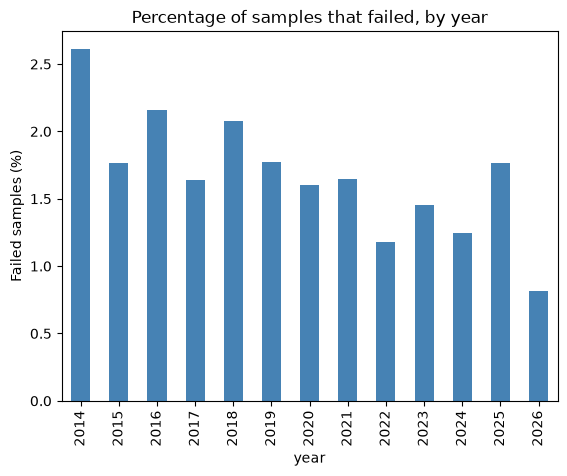

Samples: 19503
Beaches: 153
Years: 2014 to 2026
Roughly 1 failure for every 60 passes


In [ ]:
# CELL 5: CHART, SAVE THE CLEAN FILE AND PRINT THE SUMMARY
# Chart: percentage of samples that failed in each year
(samples.groupby("year")["exceedance"].mean() * 100).plot(kind="bar", color="steelblue")
plt.title("Percentage of samples that failed, by year")
plt.ylabel("Failed samples (%)")
plt.savefig("../outputs/figures/fail_rate_by_year.png")
plt.show()

# Sort by beach and date, keep the columns we need, save the clean file
samples = samples.sort_values(["beach_id", "result_date"])
columns = ["monitoring_result_id", "beach_id", "beach_name", "county_name", "water_type",
           "result_date", "year", "month", "e_coli", "enterococci",
           "sample_water_quality_status", "exceedance", "exceed_strict"]
samples[columns].to_csv("../data/processed/epa_measurements_clean.csv", index=False)


print("Samples:", len(samples))
print("Beaches:", samples["beach_id"].nunique())
print("Years:", samples["year"].min(), "to", samples["year"].max())
print("Roughly 1 failure for every", round(1 / samples["exceedance"].mean()), "passes")